# Part 1A: Dataset Audit

**Paper:** Montori et al., "A Metadata-Assisted Cascading Ensemble Classification Framework for Automatic Annotation of Open IoT Data", IEEE Internet of Things Journal, 10(15), 2023

In this notebook I check the three source datasets before any model is trained. It contains four experiments (Exp1 to Exp4) in which I:

- confirm the dimensions stated in Section IV-A of the paper
- check numerical completeness and class imbalance
- identify constant series and exact duplicates
- recreate the authors' 70:30 stratified split with seed 100
- save the exact train and test identifiers for reproducibility

## Setup

In [1]:
# load the project modules and apply the shared visual style
from pathlib import Path
import sys
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from mace.additionalExperiments import runDataAudit, saveTable
from mace.data import normaliseDatasetKey
from mace.plotting import applyPlotStyle, plotClassDistribution, saveFigure

applyPlotStyle()

## Exp1: Dataset Structure and Dimensions

- each file is loaded with its configured series length
- malformed columns, non-numeric readings and duplicate IDs cause an error
- the original CSV files are never modified

In [2]:
# run the shared dataset audit once and report the verified structure of every source file
auditTables = runDataAudit()
display(auditTables["datasetPaperCheck"])
display(auditTables["datasetStructure"])
display(auditTables["splitSummary"])

,Dataset,PaperStreams,MineStreams,PaperLength,MineLength,PaperClasses,MineClasses,HasMetadata,Match
0,UrbanObservatory,1065,1065,864,864,16,16,False,True
1,Swissex,346,346,445,445,11,11,False,True
2,ThingSpeakEU,2121,2121,96,96,21,21,True,True


,Dataset,Observations,Time-series readings,Classes,Missing numerical values,Unique IDs
0,UrbanObservatory,1065,864,16,0,1065
1,Swissex,346,445,11,0,346
2,ThingSpeakEU,2121,96,21,0,2121


,Dataset,TrainingRows,TestingRows,TestShare,Seed,Strategy
0,UrbanObservatory,745,320,30.0,100,stratified
1,Swissex,242,104,30.1,100,stratified
2,ThingSpeakEU,1484,637,30.0,100,stratified


### Findings

- All three files match Section IV-A of the paper exactly: ThingSpeak has 2121 streams of 96 readings in 21 classes, Swissex has 346 streams of 445 readings in 11 classes and Urban Observatory has 1065 streams of 864 readings in 16 classes
- No file has missing readings or duplicate IDs so no imputation or row removal was needed
- The seed-100 stratified split gives 745/320 (UrbObs), 242/104 (Swissex) and 1484/637 (ThingSpeak) training/test streams, about 30% test in each case
- Only ThingSpeak has metadata (stream names). Swissex and UrbObs contain numerical readings only so ThingSpeak is the only dataset where MACE can combine different information domains

## Exp2: Class Distribution

Accuracy can hide weak rare-class performance when one class contains most observations. The tables and plots below preserve the original imbalance rather than resampling it before the audit

,Dataset,Class,Count,Share
0,UrbanObservatory,0,84,0.078873
1,UrbanObservatory,1,37,0.034742
2,UrbanObservatory,2,121,0.113615
3,UrbanObservatory,3,37,0.034742
4,UrbanObservatory,4,133,0.124883
5,UrbanObservatory,5,37,0.034742
6,UrbanObservatory,6,33,0.030986
7,UrbanObservatory,7,34,0.031925
8,UrbanObservatory,8,13,0.012207
9,UrbanObservatory,9,25,0.023474


,Dataset,Class,Count,Share
16,Swissex,0,16,0.046243
17,Swissex,1,34,0.098266
18,Swissex,2,24,0.069364
19,Swissex,3,20,0.057803
20,Swissex,4,14,0.040462
21,Swissex,5,34,0.098266
22,Swissex,6,29,0.083815
23,Swissex,7,78,0.225434
24,Swissex,8,16,0.046243
25,Swissex,9,35,0.101156


,Dataset,Class,Count,Share
27,ThingSpeakEU,0,267,0.125884
28,ThingSpeakEU,1,433,0.204149
29,ThingSpeakEU,2,267,0.125884
30,ThingSpeakEU,3,302,0.142386
31,ThingSpeakEU,4,337,0.158887
32,ThingSpeakEU,5,45,0.021216
33,ThingSpeakEU,6,44,0.020745
34,ThingSpeakEU,7,12,0.005658
35,ThingSpeakEU,8,16,0.007544
36,ThingSpeakEU,9,4,0.001886


,Dataset,LargestClassShare,LargestClassCount,SmallestClassCount,ImbalanceRatio,ClassesBelow20Streams
0,UrbanObservatory,19.9,212,13,16.3,1
1,Swissex,22.5,78,14,5.6,3
2,ThingSpeakEU,20.4,433,4,108.2,8


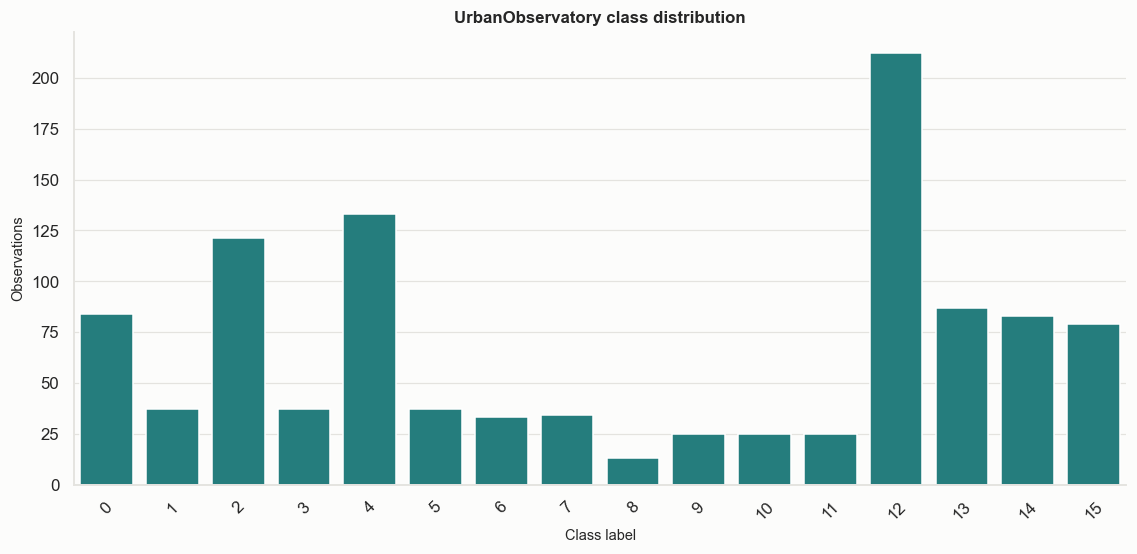

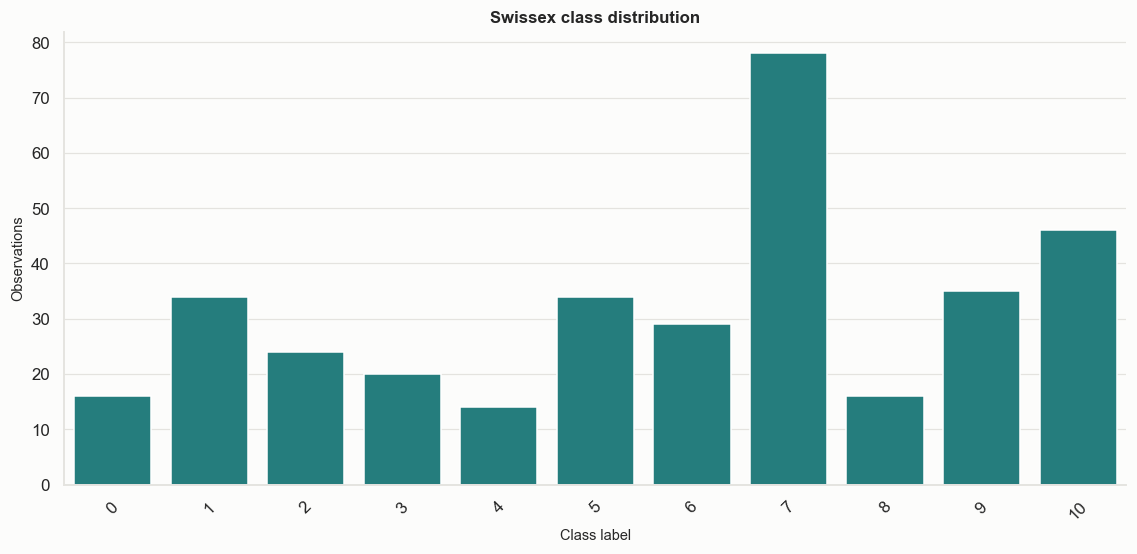

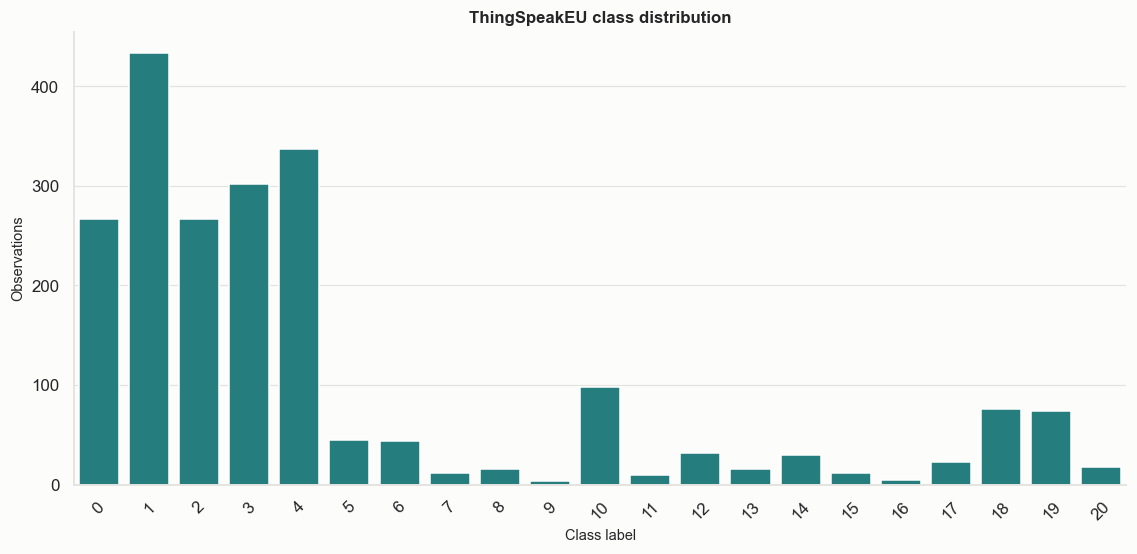

In [3]:
# compare class counts and save one descriptive plot per dataset
for displayName, table in auditTables["classDistribution"].groupby("Dataset", sort=False):
    display(table)
    figure = plotClassDistribution(table, displayName)
    saveFigure(figure, f"{normaliseDatasetKey(displayName)}ClassDistribution")

# summarise class imbalance with one row per dataset
imbalanceRows = []
for displayName, table in auditTables["classDistribution"].groupby("Dataset", sort=False):
    largestCount, smallestCount = int(table["Count"].max()), int(table["Count"].min())
    imbalanceRows.append(
        {
            "Dataset": displayName,
            "LargestClassShare": round(float(table["Share"].max()) * 100.0, 1),
            "LargestClassCount": largestCount,
            "SmallestClassCount": smallestCount,
            "ImbalanceRatio": round(largestCount / smallestCount, 1),
            "ClassesBelow20Streams": int((table["Count"] < 20).sum()),
        }
    )
imbalanceTable = saveTable(pd.DataFrame(imbalanceRows), "classImbalanceSummary")
display(imbalanceTable)

### Findings

- The largest class holds 19.9% (UrbObs), 22.5% (Swissex) and 20.4% (ThingSpeak) of streams. Always predicting the majority class would score about 20% accuracy, which is the floor every classifier should be compared against
- ThingSpeak is far more imbalanced than the other two. Its largest class has 433 streams and its smallest has 4, a ratio of about 108 to 1, compared with 212 to 13 (about 16 to 1) on UrbObs and 78 to 14 (about 6 to 1) on Swissex
- Eight ThingSpeak classes have fewer than 20 streams and the two smallest (4 and 5 streams) leave only one test stream each. Per-class results for these classes rest on a handful of predictions, which is why I report macro F1 next to accuracy and treat rare-class scores with caution

## Exp3: Constant Series, Missing Moments and Duplicate Audit

- exact constant series are counted with peak-to-peak range rather than a floating-point standard-deviation comparison
- zero-standard-deviation rows are kept as a separate compatibility check
- undefined skewness or kurtosis rows are counted directly from the raw BOS extraction
- exact duplicate series can cross a random train-test boundary
- conflicting duplicates contain the same readings with different labels and cannot be resolved from the series alone


In [4]:
# audit edge cases using the exact published split settings
display(auditTables["datasetQualityAudit"])

,dataset,observations,seriesLength,classes,exactConstantSeries,zeroStdSeries,undefinedMomentRows,duplicateGroups,conflictingDuplicateGroups,largestClassShare,crossPartitionDuplicateGroups
0,UrbanObservatory,1065,864,16,37,37,37,5,1,0.199061,3
1,Swissex,346,445,11,1,1,1,13,0,0.225434,4
2,ThingSpeakEU,2121,96,21,49,27,44,24,1,0.204149,12


### Findings

- Exactly constant series (every reading identical) number 37 in UrbObs, 1 in Swissex and 49 in ThingSpeak
- On ThingSpeak the three counts disagree. Only 27 of the 49 constant series have a standard deviation of exactly zero in floating point and SciPy returns undefined skewness or kurtosis for 44 rows. A `std == 0` check would undercount constant series so I count them with the peak-to-peak range instead
- Undefined moments are set to 0, matching the older SciPy release the authors used. Without this, Gradient Boosting rejects the input
- Exact duplicate series appear in all three datasets (5, 13 and 24 duplicate groups). Under the paper's random split, 3, 4 and 12 of these groups have copies on both sides of the train/test boundary so some test streams have an identical twin in training. UrbObs and ThingSpeak each also contain one group with identical readings but different labels
- Both issues are kept in the faithful reproduction because the paper's split contains them. I measure their effect in notebook 3 with duplicate-aware and channel-aware splits

## Exp4: Bag-of-Summaries Feature Verification

The released code uses eleven statistical features. Their order is preserved because a different order would change every fitted classifier

In [5]:
# verify finite legacy-compatible BOS values and the published feature order
featureSummary = auditTables["featureSummary"]
finiteValues = featureSummary.groupby("Dataset", sort=False)[["mean", "std", "min", "max"]].apply(
    lambda table: bool(np.isfinite(table.to_numpy()).all())
)
display(finiteValues.rename("Finite values").reset_index())
display(featureSummary)
display(auditTables["featureOrder"])

,Dataset,Finite values
0,UrbanObservatory,True
1,Swissex,True
2,ThingSpeakEU,True


,Dataset,Feature,mean,std,min,max
0,UrbanObservatory,Range,197.085824,3.822526e+02,0.000000,4.338000e+03
1,UrbanObservatory,Maximum,279.226228,4.341825e+02,0.000000,4.424000e+03
2,UrbanObservatory,StandardDeviation,31.797304,4.754810e+01,0.000000,3.954752e+02
3,UrbanObservatory,RootMeanSquare,132.647134,2.010880e+02,0.000000,1.053156e+03
4,UrbanObservatory,Mean,125.072532,1.977815e+02,0.000000,1.053151e+03
5,UrbanObservatory,Minimum,82.140404,1.857957e+02,-5.800000,1.045300e+03
6,UrbanObservatory,Quantile40,112.897527,1.938745e+02,0.000000,1.052760e+03
7,UrbanObservatory,Median,120.158210,1.960977e+02,0.000000,1.053400e+03
8,UrbanObservatory,Kurtosis,17.608857,8.264779e+01,-1.980398,8.590012e+02
9,UrbanObservatory,Skewness,1.344632,3.786007e+00,-29.342821,2.934282e+01


,Position,Feature
0,1,Range
1,2,Maximum
2,3,StandardDeviation
3,4,RootMeanSquare
4,5,Mean
5,6,Minimum
6,7,Quantile40
7,8,Median
8,9,Kurtosis
9,10,Skewness


### Findings

- All 11 features are finite for every stream in all three datasets after the handling described in Exp3
- Feature scales on ThingSpeak are extreme. Range and Maximum reach about 2.1 × 10^9 while Skewness stays within ±9.6, a gap of roughly eight orders of magnitude. UrbObs and Swissex are much milder, with Range up to about 4,300 and 3,100
- The authors' released code does not scale the features. Tree models (Random Forest, Gradient Boosting) are unaffected by scale, but distance and margin based models (kNN, SVM, Logistic Regression) are dominated by the largest features. I return to this in notebook 2 when comparing against the paper's Figure 3(b)

## Summary

| Check | UrbObs | Swissex | ThingSpeak |
|---|---|---|---|
| Streams × readings, classes | 1065 × 864, 16 | 346 × 445, 11 | 2121 × 96, 21 |
| Matches paper (Section IV-A) | Yes | Yes | Yes |
| Metadata available | No | No | Yes |
| Majority-class share | 19.9% | 22.5% | 20.4% |
| Largest / smallest class | 212 / 13 | 78 / 14 | 433 / 4 |
| Exactly constant series | 37 | 1 | 49 |
| Duplicate groups crossing the split | 3 of 5 | 4 of 13 | 12 of 24 |

## Audit decision

- The CSV files are used as released with no rows removed so every later result uses the same data as the paper
- The paper's split (stratified 70:30, seed 100) is kept for the direct comparison in notebook 2
- Exact constants, zero-standard-deviation rows and undefined-moment rows are reported as three separate counts, because they differ on ThingSpeak
- Undefined skewness and kurtosis are set to 0 only in the faithful reproduction path
- Duplicate-aware and channel-aware splits are held back for the critical analysis in notebook 3
- Macro-averaged and per-class metrics are reported alongside accuracy because all three datasets are imbalanced